# Extension - diversity, test-set uncertainty and partial dependence

**Question.** How different are the models' mistakes, how certain are the test scores, and what drives the predictions? Also three checks added after the final evaluation.

**Brief and report.** Parts G and H. Report Sections 4.3 (Table 9), 7 (Table 14) and 8.

**The later checks.** They use training CV or the saved test predictions only. They answer follow-up questions but do not change the recommendation.

The setup cell below makes the repository root the working folder, so `src/` can be imported, and defines two helpers: `results(name)` reads a table from `results/` and `show(...)` displays saved figures from `reports/figures/`.

In [1]:
import os, sys
from pathlib import Path
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import Image, Markdown, display
from src.common import ROOT
pd.set_option('display.precision', 3)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

def show(*names):
    """Display saved figures from reports/figures/."""
    for name in names:
        display(Markdown(f'**reports/figures/{name}**'))
        display(Image(filename=str(ROOT / 'reports' / 'figures' / name)))

def results(name):
    return pd.read_csv(ROOT / 'results' / name)

### 1. Diversity, test-set uncertainty and partial dependence
`ensemble_interpretation()` in `src/interpret.py` produces five results:
- how differently the three models err (double fault, disagreement, correlation)
- bootstrap intervals for every test metric, and paired comparisons with Voting
- AP by arrival week
- partial dependence of the saved model on lead time, ADR and special requests
- the score when the removed duplicate records are counted again

**How to read the output.** A paired difference whose interval includes 0 is not a real lead.

Interpretation | interpretation: Diversity, test uncertainty, week bootstrap, PDP and population checks saved.


,first,second,selected_pair,metric,observed,mean,sd,ci_low,ci_high,n
0,Logistic Regression,Random Forest,False,q_statistic,0.974,0.974,7.511e-04,0.972,0.975,600
1,Logistic Regression,Random Forest,False,double_fault,0.162,0.162,1.236e-03,0.159,0.164,600
2,Logistic Regression,Random Forest,False,disagreement,0.082,0.082,1.026e-03,0.080,0.084,600
3,Logistic Regression,Random Forest,False,probability_correlation,0.824,0.824,1.434e-03,0.821,0.827,600
4,Logistic Regression,Hist Gradient Boosting,False,q_statistic,0.984,0.984,4.940e-04,0.983,0.985,600
5,Logistic Regression,Hist Gradient Boosting,False,double_fault,0.170,0.170,1.225e-03,0.167,0.172,600
6,Logistic Regression,Hist Gradient Boosting,False,disagreement,0.066,0.066,9.250e-04,0.065,0.068,600
7,Logistic Regression,Hist Gradient Boosting,False,probability_correlation,0.868,0.868,1.193e-03,0.866,0.870,600
8,Random Forest,Hist Gradient Boosting,True,q_statistic,0.994,0.994,2.278e-04,0.994,0.995,600
9,Random Forest,Hist Gradient Boosting,True,double_fault,0.174,0.174,1.277e-03,0.172,0.177,600


,model,metric,observed,mean,sd,ci_low,ci_high,n
0,Logistic Regression,accuracy,0.795,0.795,0.003,0.790,0.800,500
1,Logistic Regression,balanced_accuracy,0.677,0.677,0.004,0.669,0.685,500
2,Logistic Regression,precision,0.706,0.706,0.008,0.691,0.721,500
3,Logistic Regression,recall,0.419,0.419,0.007,0.404,0.434,500
4,Logistic Regression,f1,0.526,0.526,0.007,0.511,0.540,500
5,Logistic Regression,roc_auc,0.787,0.788,0.004,0.780,0.795,500
6,Logistic Regression,pr_auc,0.633,0.633,0.006,0.621,0.646,500
7,Logistic Regression,brier,0.151,0.151,0.001,0.148,0.153,500
8,Random Forest,accuracy,0.811,0.811,0.003,0.806,0.817,500
9,Random Forest,balanced_accuracy,0.716,0.716,0.004,0.708,0.723,500


,option,reference,metric,observed,mean,sd,ci_low,ci_high,n,p_value,p_holm
0,Logistic Regression,Voting,pr_auc,-6.481e-02,-6.478e-02,3.809e-03,-7.259e-02,-5.752e-02,1000,9.990e-04,0.004
1,Random Forest,Voting,pr_auc,-1.825e-03,-1.822e-03,1.040e-03,-3.864e-03,1.297e-04,1000,7.592e-02,0.076
2,Hist Gradient Boosting,Voting,pr_auc,-9.389e-03,-9.402e-03,1.204e-03,-1.167e-02,-7.034e-03,1000,9.990e-04,0.004
3,Stacking,Voting,pr_auc,3.770e-04,3.794e-04,1.503e-04,9.044e-05,6.728e-04,1000,1.399e-02,0.028


,model,arrival_weeks,observed,mean,sd,ci_low,ci_high,n
0,Hist Gradient Boosting (default),36,0.553,0.554,0.014,0.530,0.582,300
1,Hist Gradient Boosting (tuned),36,0.552,0.553,0.013,0.532,0.581,300
2,Logistic Regression (default),36,0.552,0.552,0.012,0.530,0.577,300
3,Logistic Regression (tuned),36,0.552,0.552,0.013,0.530,0.577,300
4,Random Forest (default),36,0.533,0.534,0.014,0.510,0.563,300
5,Random Forest (tuned),36,0.537,0.538,0.014,0.515,0.567,300
6,Voting (tuned),36,0.548,0.549,0.014,0.527,0.578,300


,population,rows,effective_rows,positive_fraction,metric,observed,mean,sd,ci_low,ci_high,n
0,unique bookings,17519,17519.0,0.271,pr_auc,0.698,0.698,0.006,0.687,0.710,300
1,unique bookings,17519,17519.0,0.271,accuracy,0.812,0.812,0.003,0.806,0.817,300
2,unique bookings,17519,17519.0,0.271,f1,0.591,0.591,0.007,0.576,0.604,300
3,unique bookings,17519,17519.0,0.271,roc_auc,0.838,0.838,0.003,0.831,0.844,300
4,unique bookings,17519,17519.0,0.271,brier,0.134,0.134,0.001,0.132,0.137,300
5,weighted by source duplicates,17519,24098.0,0.366,pr_auc,0.841,0.840,0.011,0.817,0.859,300
6,weighted by source duplicates,17519,24098.0,0.366,accuracy,0.815,0.815,0.006,0.804,0.826,300
7,weighted by source duplicates,17519,24098.0,0.366,f1,0.706,0.706,0.014,0.677,0.734,300
8,weighted by source duplicates,17519,24098.0,0.366,roc_auc,0.878,0.878,0.006,0.866,0.890,300
9,weighted by source duplicates,17519,24098.0,0.366,brier,0.132,0.132,0.003,0.126,0.138,300


**reports/figures/fig_H_12_partial_dependence.png**

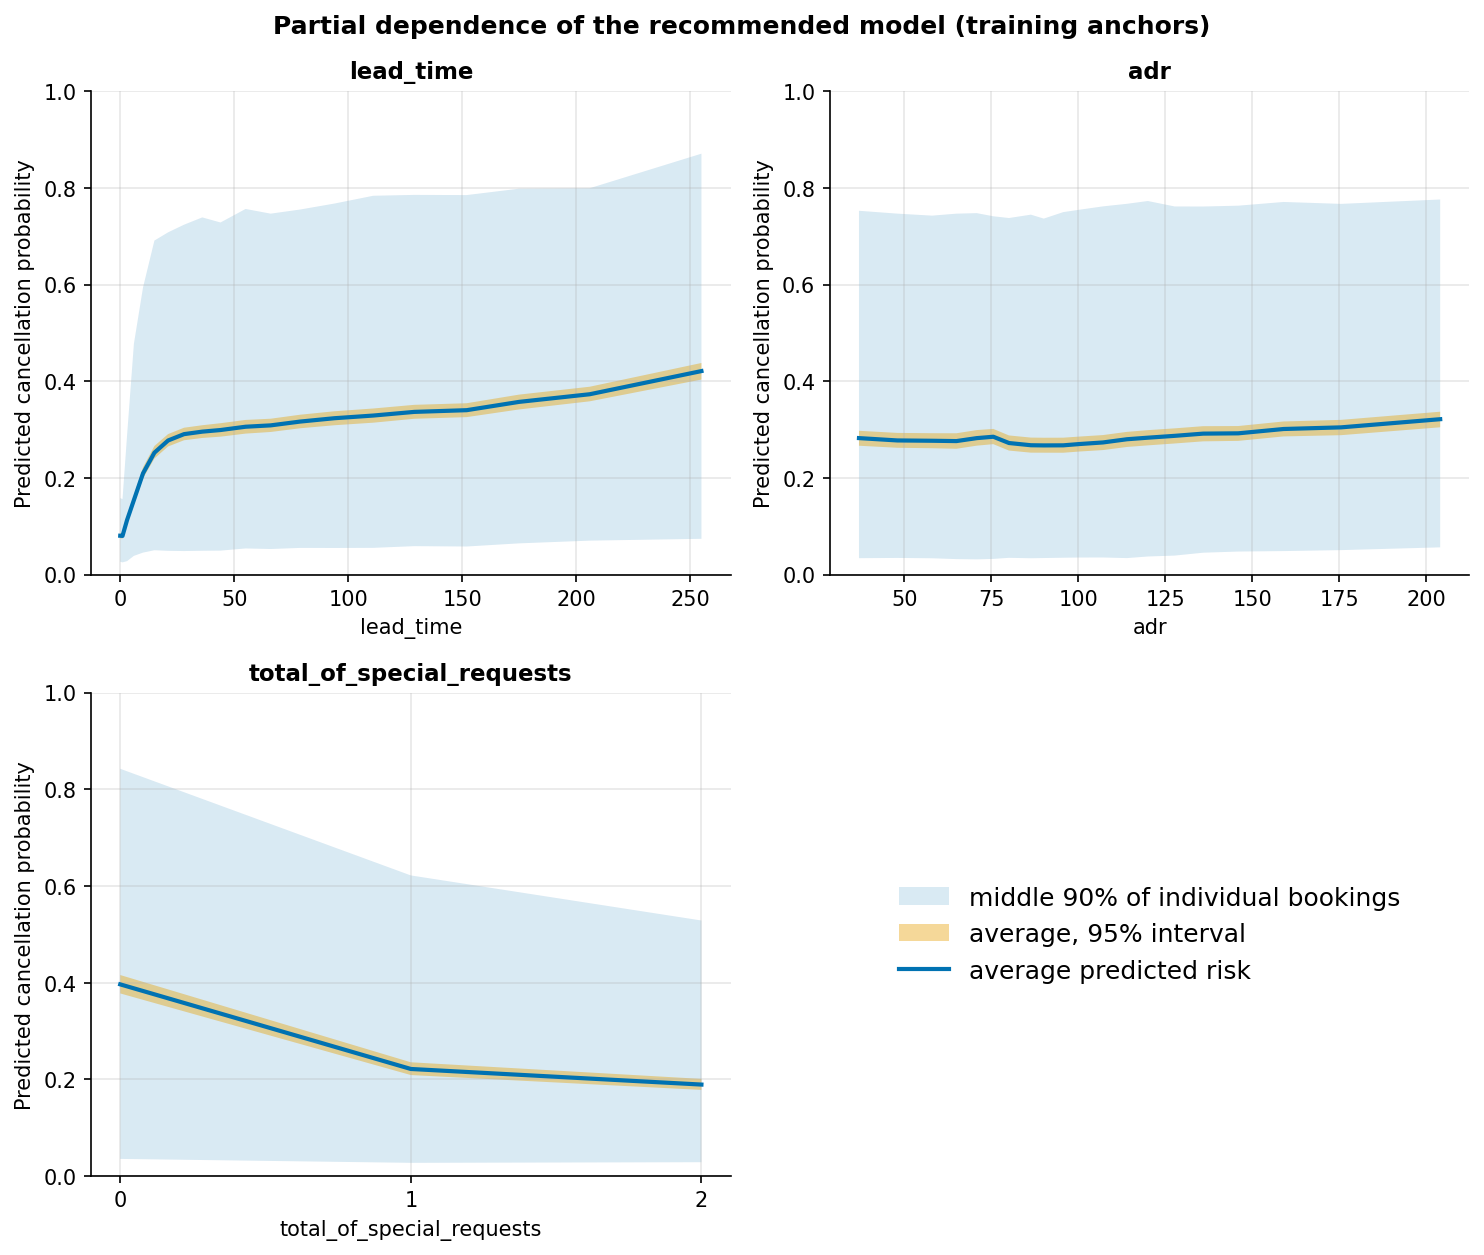

**reports/figures/fig_H_13_holdout_uncertainty.png**

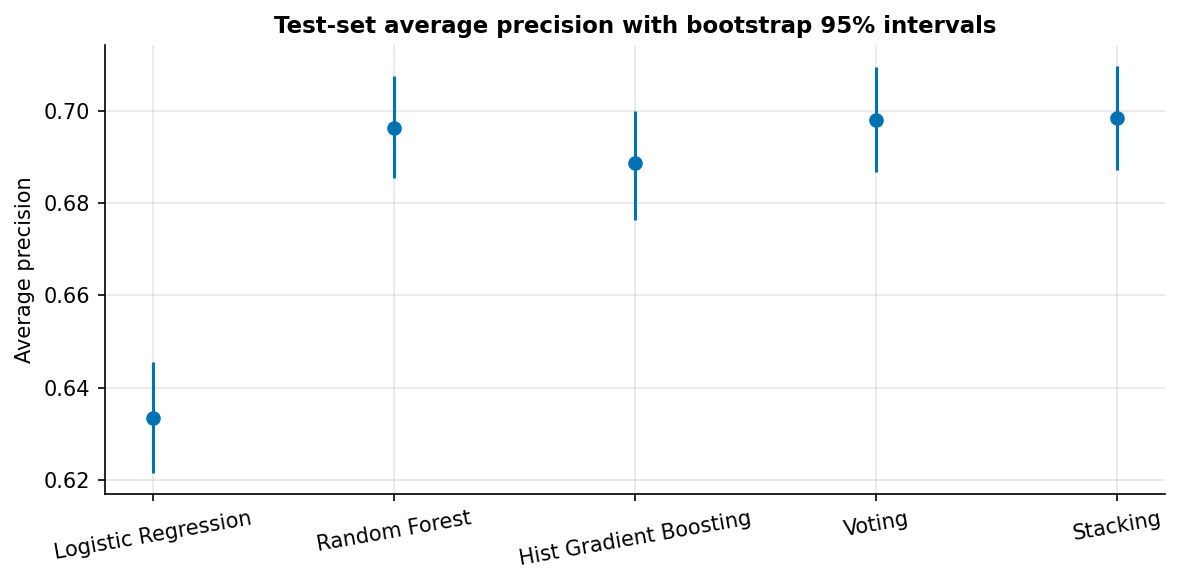

In [2]:
from src.interpret import ensemble_interpretation
diversity, (intervals, comparison), weeks, pdp, population = ensemble_interpretation()
display(diversity)
display(intervals)
display(comparison)
display(weeks)
display(population)
show('fig_H_12_partial_dependence.png', 'fig_H_13_holdout_uncertainty.png')

### 2. Alternative ensemble pairs (training CV only)

Soft voting of every pair of tuned models, scored on the same five group-aware training folds. This tests the reason for leaving logistic regression out of the ensemble; it does not use the test set and does not change the recommendation.

In [3]:
from src.evaluate import alternative_pairs
pairs, pair_comparisons = alternative_pairs()
display(pairs)
display(pair_comparisons)

Alternative pairs | alternative pair: Voting of Logistic Regression + Random Forest: CV AP 0.681


Alternative pairs | alternative pair: Voting of Logistic Regression + Hist Gradient Boosting: CV AP 0.673


Alternative pairs | alternative pair: Voting of Random Forest + Hist Gradient Boosting: CV AP 0.694


,pair,selected_pair,pr_auc_mean,pr_auc_std,train_pr_auc_mean,fit_seconds
0,Logistic Regression + Random Forest,False,0.681,0.005,0.891,45.490
1,Logistic Regression + Hist Gradient Boosting,False,0.673,0.005,0.730,26.380
2,Random Forest + Hist Gradient Boosting,True,0.694,0.006,0.913,65.036


,option,reference,metric,mean,sd,ci_low,ci_high,p_value,n,validation_train_ratio,p_holm
0,Logistic Regression + Hist Gradient Boosting,Random Forest + Hist Gradient Boosting,pr_auc,-0.021,0.004,-0.028,-0.014,1.142e-03,5,0.25,0.001
1,Logistic Regression + Random Forest,Random Forest + Hist Gradient Boosting,pr_auc,-0.013,0.002,-0.017,-0.009,6.842e-04,5,0.25,0.001


### 3. Extra features, training CV only
`booking_time_features()` in `src/evaluate.py` tests two ideas on the tuned forest and boosting models:
- **Calendar fields known at booking:** booking month and weekday (arrival date minus lead time), and arrival weekday.
- **Target encoding:** scikit-learn's `TargetEncoder` replaces the one-hot columns for agent and company. It is cross-fitted inside each fold, so a row's own label never sets its code.

Each option is compared with the reference pipeline on the same folds, with Holm's adjustment over six comparisons. The reference rows must reproduce the tuned CV AP from notebook 03.

**How to read the output.** A gain counts only if its Holm-adjusted p-value is below 0.05. Neither option was adopted, because the test set had already been used.

In [4]:
from src.evaluate import booking_time_features
booking_time, booking_time_comparisons = booking_time_features()
display(booking_time)
display(booking_time_comparisons)

Extra features | booking-time features: Random Forest, reference: CV AP 0.6896


Extra features | booking-time features: Random Forest, calendar features: CV AP 0.6950


Extra features | booking-time features: Random Forest, target-encoded agent and company: CV AP 0.6898


Extra features | booking-time features: Random Forest, both: CV AP 0.6941


Extra features | booking-time features: Hist Gradient Boosting, reference: CV AP 0.6873


Extra features | booking-time features: Hist Gradient Boosting, calendar features: CV AP 0.6899


Extra features | booking-time features: Hist Gradient Boosting, target-encoded agent and company: CV AP 0.6870


Extra features | booking-time features: Hist Gradient Boosting, both: CV AP 0.6885


,model,configuration,pr_auc_mean,pr_auc_std,roc_auc_mean,fit_seconds
0,Random Forest,reference,0.690,0.007,0.831,42.181
1,Random Forest,calendar features,0.695,0.006,0.833,53.853
2,Random Forest,target-encoded agent and company,0.690,0.006,0.831,40.772
3,Random Forest,both,0.694,0.006,0.834,52.257
4,Hist Gradient Boosting,reference,0.687,0.006,0.831,21.856
5,Hist Gradient Boosting,calendar features,0.690,0.006,0.833,28.049
6,Hist Gradient Boosting,target-encoded agent and company,0.687,0.005,0.830,2429.329
7,Hist Gradient Boosting,both,0.689,0.005,0.832,25.127


,option,reference,metric,mean,sd,ci_low,ci_high,p_value,n,validation_train_ratio,model,p_holm
0,both,reference,pr_auc,4.556e-03,0.002,3.142e-04,0.009,0.041,5,0.25,Random Forest,0.211
1,calendar features,reference,pr_auc,5.382e-03,0.003,6.106e-04,0.010,0.035,5,0.25,Random Forest,0.211
2,target-encoded agent and company,reference,pr_auc,2.207e-04,0.002,-2.621e-03,0.003,0.840,5,0.25,Random Forest,1.000
3,both,reference,pr_auc,1.188e-03,0.002,-2.426e-03,0.005,0.413,5,0.25,Hist Gradient Boosting,1.000
4,calendar features,reference,pr_auc,2.573e-03,0.002,-1.638e-03,0.007,0.165,5,0.25,Hist Gradient Boosting,0.660
5,target-encoded agent and company,reference,pr_auc,-2.995e-04,0.002,-4.004e-03,0.003,0.833,5,0.25,Hist Gradient Boosting,1.000


### 4. Business success measure
`precision_at_capacity()` reads the saved test predictions; nothing is refitted. It reports precision and recall if staff can review only the riskiest 5%, 10% or 20% of bookings (report Section 8.1).

In [5]:
from src.evaluate import precision_at_capacity
display(precision_at_capacity())

,model,review_share,bookings_reviewed,precision,recall
0,Logistic Regression,0.05,876,0.852,0.157
1,Logistic Regression,0.10,1752,0.764,0.282
2,Logistic Regression,0.20,3504,0.658,0.486
3,Random Forest,0.05,876,0.906,0.167
4,Random Forest,0.10,1752,0.824,0.304
5,Random Forest,0.20,3504,0.704,0.520
6,Hist Gradient Boosting,0.05,876,0.908,0.168
7,Hist Gradient Boosting,0.10,1752,0.804,0.297
8,Hist Gradient Boosting,0.20,3504,0.696,0.514
9,Voting,0.05,876,0.914,0.169
